Plotting Variables

In [7]:
import uproot
import matplotlib.pyplot as plt
import numpy as np


In [8]:
files = {
    "DY": "data/DY-train.root",
    "Higgs": "data/Higgs-train.root",
    "Top": "data/Top-train.root",
    "WW": "data/WW-train.root"
}

In [11]:
with uproot.open("data/WW-train.root") as f:
    print(f.keys())
    b = f["Events"]
    print(b.num_entries)
    for branches in b.keys():
        print(branches)

['Events;1']
1011000
Electron_charge
Electron_eta
Electron_mass
Electron_mvaFall17V2Iso_WP90
Electron_phi
Electron_pt
Jet_btagDeepFlavB
Jet_eta
Jet_jetId
Jet_mass
Jet_phi
Jet_pt
Jet_puId
Muon_charge
Muon_eta
Muon_mass
Muon_pfRelIso04_all
Muon_phi
Muon_pt
Muon_tightId
PuppiMET_phi
PuppiMET_pt
dphill
mjj
mll
mth
mtw2
nJet
ptll


DY:
  Number of entries: 5626820
  Minimum: 0.0027599838
  Maximum: 1815.6514
Higgs:
  Number of entries: 366908
  Minimum: 0.024556182
  Maximum: 449.09555
Top:
  Number of entries: 96483
  Minimum: 0.0072845137
  Maximum: 1566.4893
WW:
  Number of entries: 255232
  Minimum: 0.08953221
  Maximum: 1931.2258


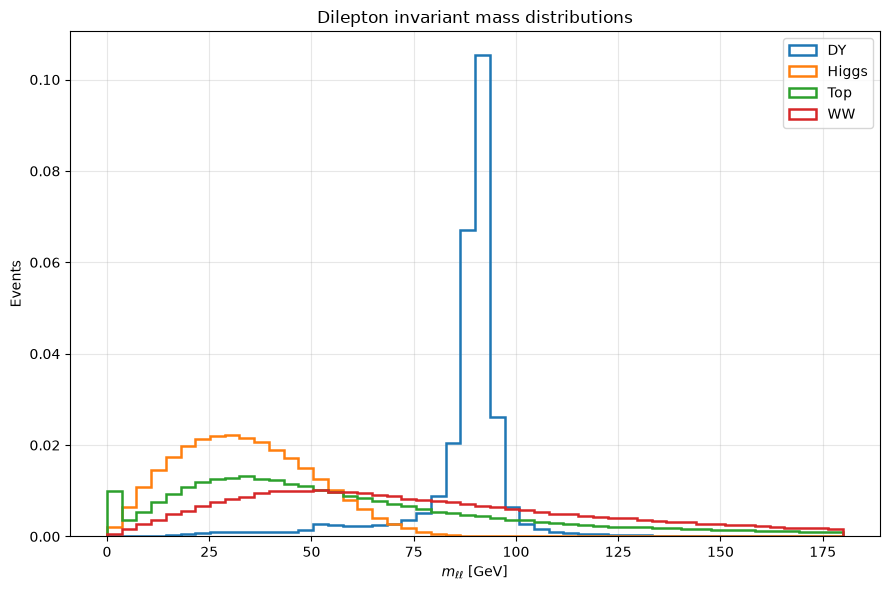

In [12]:
plt.figure(figsize=(9, 6))

for label, filename in files.items():

    with uproot.open(filename) as f:
        mll = f["Events"].arrays(["mll"], library="np")["mll"]

    # Remove undefined or non-physical values
    mll = mll[mll > 0]

    print(f"{label}:")
    print("  Number of entries:", len(mll))
    print("  Minimum:", np.min(mll))
    print("  Maximum:", np.max(mll))

    plt.hist(
        mll,
        bins=50,
        range=(20, 180),
        histtype="step",
        linewidth=1.8,
        density=True,
        label=label
        
    )

plt.xlabel(r"$m_{\ell\ell}$ [GeV]")
plt.ylabel("Events")
plt.title(r"Dilepton invariant mass distributions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


DY:
  Number of entries: 21849377
  Minimum: -999.0
  Maximum: 3.1415913
Higgs:
  Number of entries: 1439000
  Minimum: -999.0
  Maximum: 3.1415837
Top:
  Number of entries: 7746000
  Minimum: -999.0
  Maximum: 3.141515
WW:
  Number of entries: 1011000
  Minimum: -999.0
  Maximum: 3.1415837


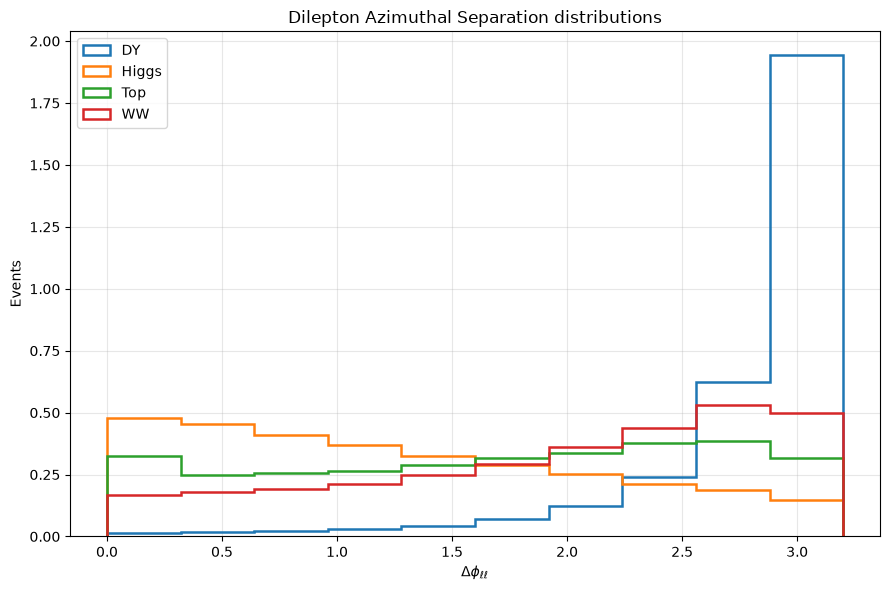

In [16]:

plt.figure(figsize=(9, 6))

for label, filename in files.items():

    with uproot.open(filename) as f:
        dphill = f["Events"].arrays(["dphill"], library="np")["dphill"]

    # Remove undefined or non-physical values
#     mll = mll[mll > 0]

    print(f"{label}:")
    print("  Number of entries:", len(dphill))
    print("  Minimum:", np.min(dphill))
    print("  Maximum:", np.max(dphill))

    plt.hist(
        dphill,
        bins=10,
        range=(0, 3.2),
        histtype="step",
        linewidth=1.8,
        density=True,
        label=label
        
    )

plt.xlabel(r"$\Delta \phi_{\ell\ell}$")
plt.ylabel("Events")
plt.title(r"Dilepton Azimuthal Separation distributions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()




In [ ]:

plt.figure(figsize=(9, 6))

for label, filename in files.items():

    with uproot.open(filename) as f:
        mth = f["Events"].arrays(["mth"], library="np")["mth"]

    # Remove undefined or non-physical values
#     mll = mll[mll > 0]

    print(f"{label}:")
    print("  Number of entries:", len(mth))
    print("  Minimum:", np.min(mth))
    print("  Maximum:", np.max(mth))

    plt.hist(
        mth,
        bins=10,
        range=(0, 3.2),
        histtype="step",
        linewidth=1.8,
        density=True,
        label=label
        
    )

plt.xlabel(r"$\Delta \phi_{\ell\ell}$")
plt.ylabel("Events")
plt.title(r"Dilepton Azimuthal Separation distributions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()




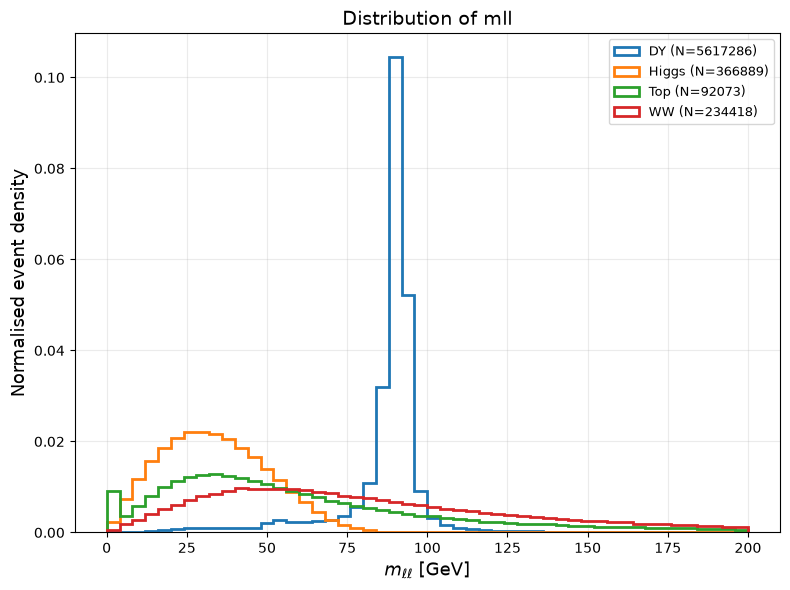

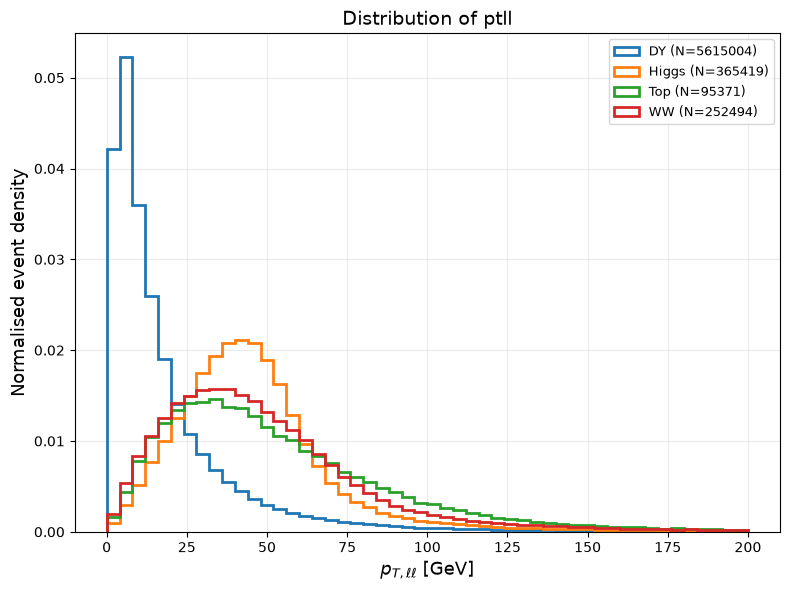

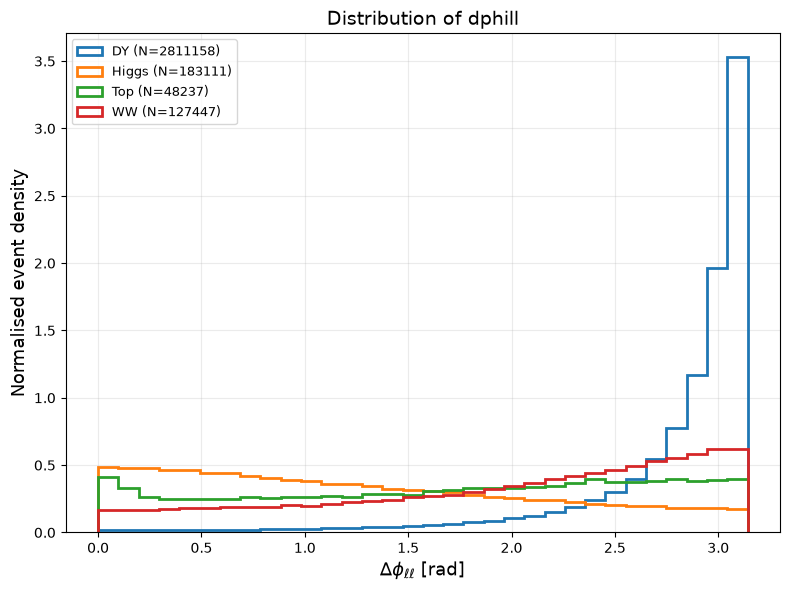

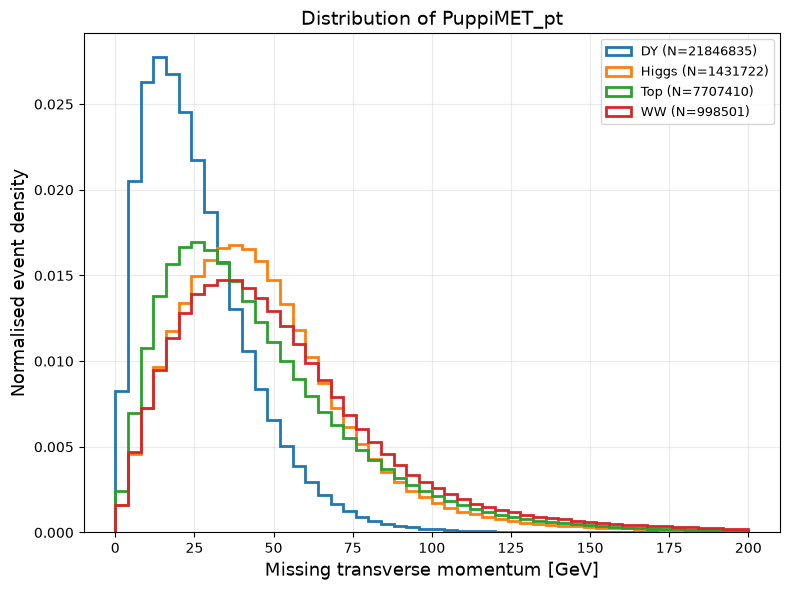

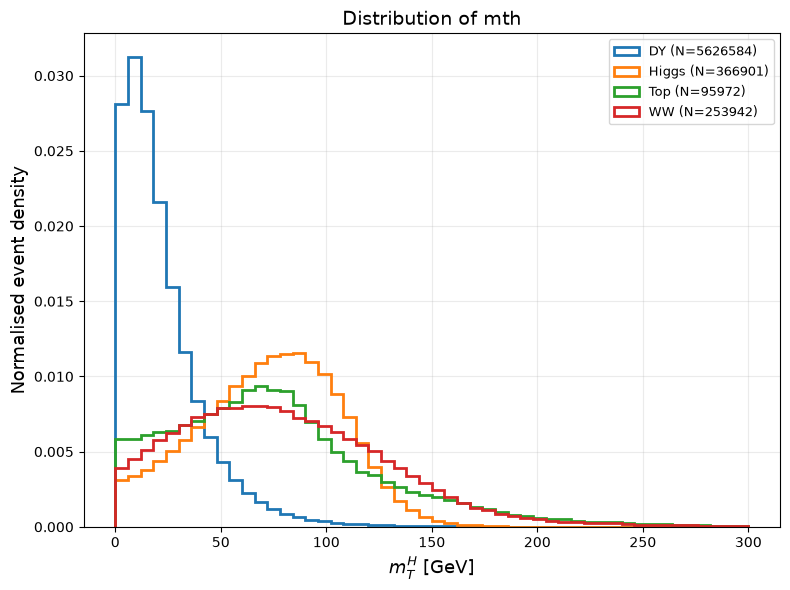

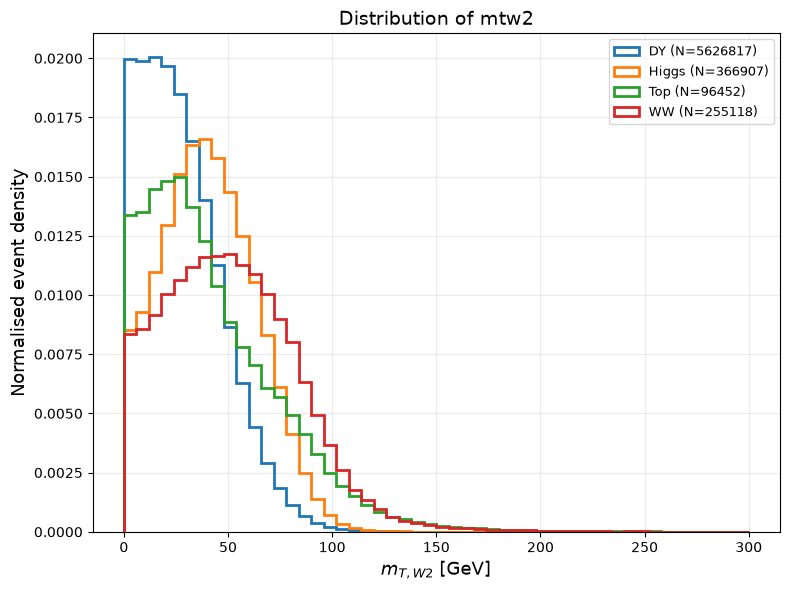

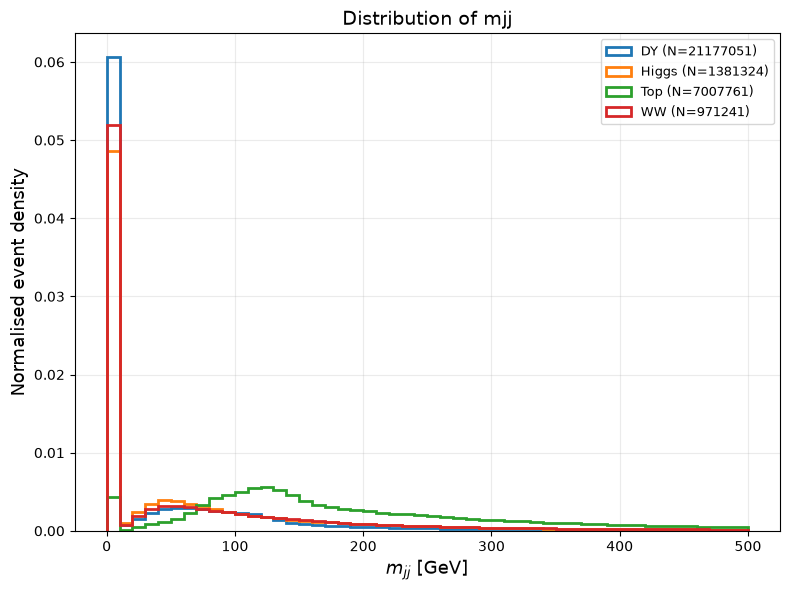

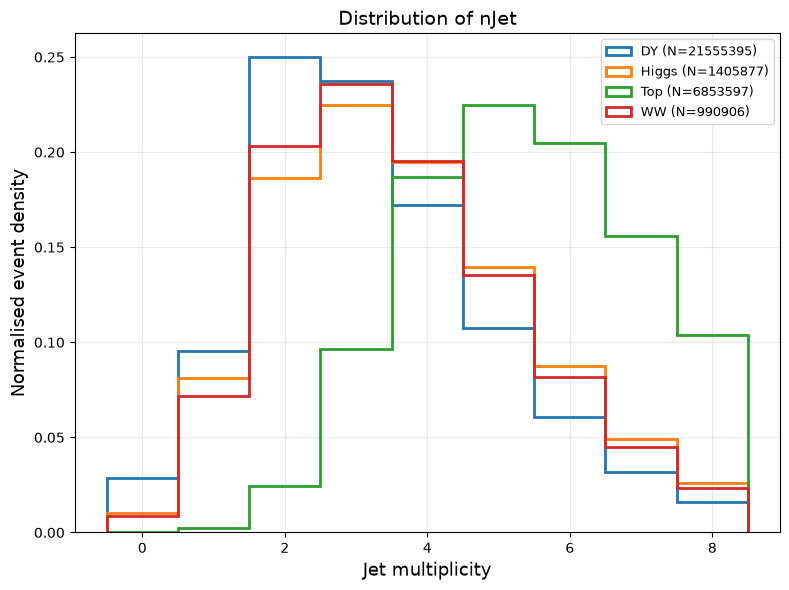

Plots saved in important_variable_plots/


In [18]:
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
import os

files = {
    "DY": "data/DY-train.root",
    "Higgs": "data/Higgs-train.root",
    "Top": "data/Top-train.root",
    "WW": "data/WW-train.root"
}

variables = {
    "mll": (r"$m_{\ell\ell}$ [GeV]", (0, 200), 50),
    "ptll": (r"$p_{T,\ell\ell}$ [GeV]", (0, 200), 50),
    "dphill": (r"$\Delta\phi_{\ell\ell}$ [rad]", (0, np.pi), 32),
    "PuppiMET_pt": ("Missing transverse momentum [GeV]", (0, 200), 50),
    "mth": (r"$m_T^H$ [GeV]", (0, 300), 50),
    "mtw2": (r"$m_{T,W2}$ [GeV]", (0, 300), 50),
    "mjj": (r"$m_{jj}$ [GeV]", (0, 500), 50),
    "nJet": ("Jet multiplicity", (-0.5, 8.5), 9)
}

os.makedirs("important_variable_plots", exist_ok=True)

for var, (xlabel, plot_range, nbins) in variables.items():
    fig, ax = plt.subplots(figsize=(8, 6))
    plotted = False

    for label, filename in files.items():
        if not os.path.exists(filename):
            print(f"File not found: {filename}")
            continue

        try:
            with uproot.open(filename) as root_file:
                tree = root_file["Events"]

                # Read the field through arrays(), compatible with RNTuple
                if var not in tree.keys():
                    print(f"Branch '{var}' not found in {filename}")
                    continue

                data = tree.arrays([var], library="ak")
                values = ak.to_numpy(data[var])

            # These variables should be scalar, one value per event
            if values.ndim != 1:
                print(f"Skipping non-scalar variable '{var}' in {filename}")
                continue

            values = values[np.isfinite(values)]
            low, high = plot_range
            values = values[(values >= low) & (values <= high)]

            if len(values) == 0:
                print(f"No valid values for {var} in {filename}")
                continue

            ax.hist(
                values,
                bins=nbins,
                range=plot_range,
                histtype="step",
                linewidth=2,
                density=True,
                label=f"{label} (N={len(values)})"
            )
            plotted = True

        except Exception as e:
            print(f"Error reading {var} from {filename}: {e}")

    ax.set_xlabel(xlabel, fontsize=13)
    ax.set_ylabel("Normalised event density", fontsize=13)
    ax.set_title(f"Distribution of {var}", fontsize=14)
    ax.grid(alpha=0.25)

    if plotted:
        ax.legend(fontsize=9)

    fig.tight_layout()
    fig.savefig(f"important_variable_plots/{var}.png", dpi=150)

    if plotted:
        plt.show()

    plt.close(fig)

print("Plots saved in important_variable_plots/")